# Chapitre 4 - Cours 6 : Embeddings et index vectoriels

Ce notebook couvre la sous-section *Vector Embeddings* de la section
*Multidimensional and Full-Text Indexes*, nouvelle dans la 2e édition : la recherche
sémantique, les embeddings, les distances cosinus et euclidienne, et les trois familles
d'index vectoriels citées par le livre (plat, IVF, HNSW). Le livre renvoie aux articles
pour le détail des algorithmes : nous les implémentons (`ddia/storage_vectors.py`) et
mesurons le compromis rappel / coût.

**Plan.**

1. De la recherche plein texte à la recherche sémantique.
2. Mesurer la proximité : cosinus et distance euclidienne.
3. L'index plat : exact mais linéaire.
4. L'index IVF : partitionner l'espace, sonder quelques partitions.
5. L'index HNSW : un graphe de proximité à plusieurs couches.
6. Pourquoi pas un R-tree ? La malédiction de la dimension.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage_vectors as V
from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. De la recherche plein texte à la recherche sémantique (section *Vector Embeddings*)

La recherche plein texte trouve les documents qui contiennent **les mots** de la
requête (cours 4), avec un peu de tolérance aux fautes. La **recherche sémantique** vise
le **sens** : une page d'aide intitulée « résilier son abonnement » doit sortir pour la
requête « comment fermer mon compte », sans aucun mot commun. C'est une brique des
applications d'IA, par exemple la génération augmentée par la recherche (RAG), qui
injecte des documents trouvés dans la réponse d'un grand modèle de langage.

**L'embedding.** Un **modèle d'embedding** (souvent un réseau de neurones, parfois un
LLM) transforme un document en un **vecteur de nombres flottants**, un point dans un
espace à plusieurs centaines ou milliers de dimensions. Le modèle est entraîné pour que
des documents **proches par le sens** donnent des **points proches**. On ne cherche pas
à interpréter chaque coordonnée. Les premiers modèles travaillaient sur du texte
(Word2Vec, BERT, GPT) ; il en existe pour les images, le son, la vidéo, et des modèles
**multimodaux** qui placent texte et images dans le même espace.

Attention au faux ami : le **traitement vectorisé** du cours 5 désigne des lots de
valeurs traités par des instructions spécialisées ; ici, un **vecteur** est un point de
l'espace.

Un exemple jouet en trois dimensions (valeurs inventées pour l'illustration) :

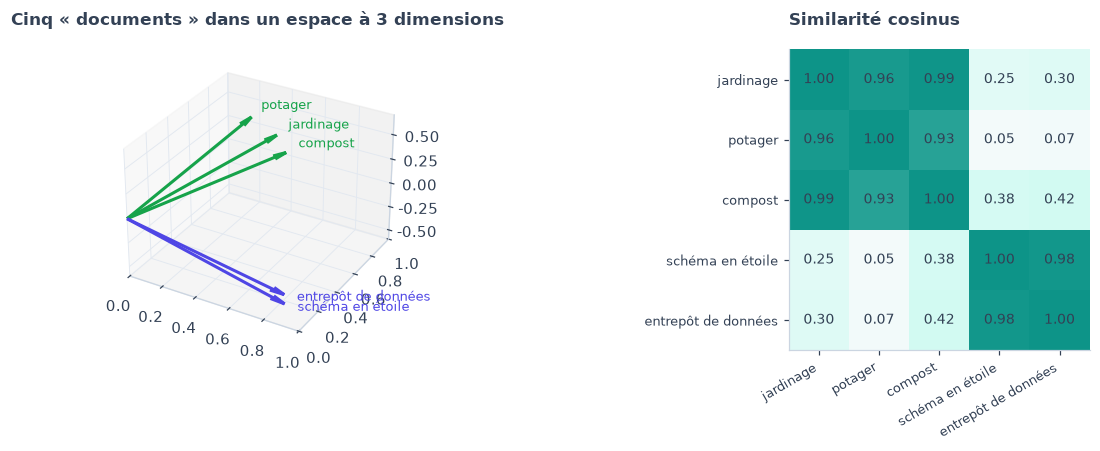

In [2]:
jouet = pd.DataFrame({
    "jardinage": [0.42, 0.80, 0.39], "potager": [0.33, 0.69, 0.62], "compost": [0.51, 0.74, 0.30],
    "schéma en étoile": [0.88, 0.07, -0.46], "entrepôt de données": [0.80, 0.21, -0.55],
}, index=["x", "y", "z"]).T
sims = pd.DataFrame({a: {b: V.cosine_similarity(jouet.loc[a], jouet.loc[b]) for b in jouet.index}
                     for a in jouet.index})
fig = plt.figure(figsize=(12, 4.2))
ax = fig.add_subplot(1, 2, 1, projection="3d")
for nom, c in zip(jouet.index, [GREEN, GREEN, GREEN, INDIGO, INDIGO]):
    v = jouet.loc[nom].to_numpy()
    ax.quiver(0, 0, 0, *v, color=c, arrow_length_ratio=0.08, lw=2)
    ax.text(*(v * 1.08), nom, fontsize=8.5, color=c)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_zlim(-0.6, 0.7)
ax.set_title("Cinq « documents » dans un espace à 3 dimensions", fontsize=11)
ax2 = fig.add_subplot(1, 2, 2)
ax2.imshow(sims.values, cmap="ddia_div", vmin=-1, vmax=1)
for i in range(len(sims)):
    for j in range(len(sims)):
        ax2.text(j, i, f"{sims.values[i, j]:.2f}", ha="center", va="center", fontsize=9, color=SLATE)
ax2.set_xticks(range(len(sims)), sims.columns, rotation=30, ha="right", fontsize=8.5)
ax2.set_yticks(range(len(sims)), sims.index, fontsize=8.5)
ax2.grid(False)
ax2.set_title("Similarité cosinus", fontsize=11)
plt.tight_layout(); plt.show()

Les trois documents de jardinage forment un groupe (similarités supérieures à 0,9), les
deux documents sur l'analytique un autre ; entre les deux groupes, la similarité est
nettement plus faible (de 0,05 à 0,4).

**Le pipeline.** À l'indexation, chaque document passe par le modèle d'embedding et son
vecteur est rangé dans un **index vectoriel**. À la requête, le texte saisi (et
éventuellement un contexte, comme la position de l'utilisateur) passe par le **même**
modèle, et l'index renvoie les documents dont les vecteurs sont les plus proches.

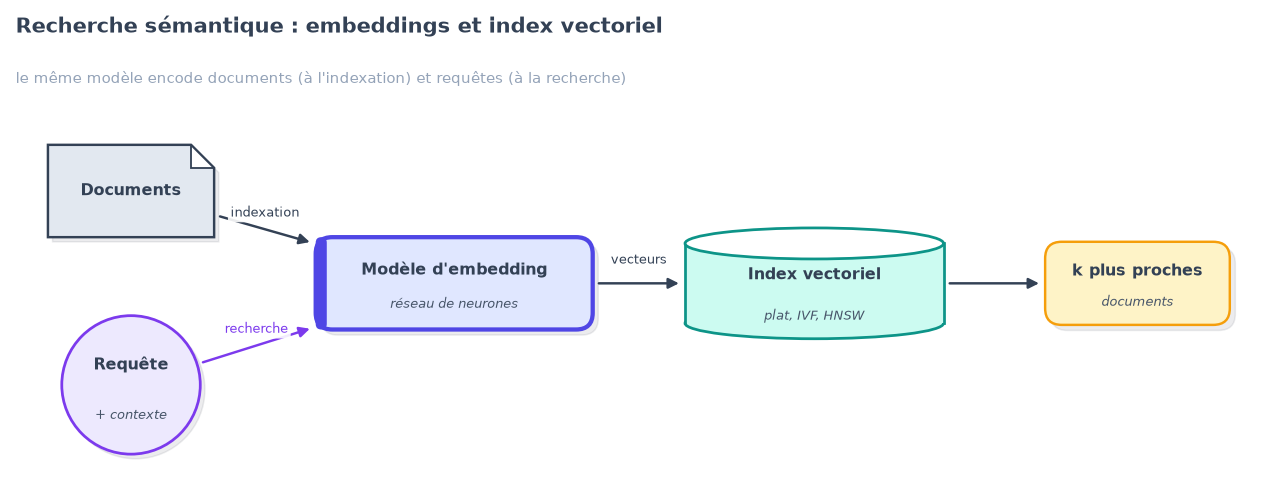

In [3]:
d = Diagram(13.5, 4.0, title="Recherche sémantique : embeddings et index vectoriel",
            subtitle="le même modèle encode documents (à l'indexation) et requêtes (à la recherche)")
d.box("docs", 1.3, 3.0, "Documents", kind="doc", color=SLATE, w=1.8, h=1.0)
d.box("q", 1.3, 0.9, "Requête", sub="+ contexte", kind="user", color=VIOLET, w=1.5)
d.box("emb", 4.8, 2.0, "Modèle d'embedding", sub="réseau de neurones", kind="model", color=INDIGO, w=3.0, h=1.0)
d.box("idx", 8.7, 2.0, "Index vectoriel", sub="plat, IVF, HNSW", kind="db", color=TEAL, w=2.8, h=1.2)
d.box("res", 12.2, 2.0, "k plus proches", sub="documents", color=AMBER, w=2.0)
d.arrow("docs", "emb", "indexation", color=SLATE)
d.arrow("q", "emb", "recherche", color=VIOLET)
d.arrow("emb", "idx", "vecteurs", label_offset=(0, 0.25))
d.arrow("idx", "res")
d.show()

> **À retenir.** Un embedding place un document dans un espace où la proximité
> géométrique reflète la proximité de sens. La recherche sémantique devient une
> recherche des **plus proches voisins** de la requête.

## 2. Mesurer la proximité : cosinus et distance euclidienne (section *Vector Embeddings*)

Deux mesures dominent :

- la **similarité cosinus** $\cos(a, b) = \dfrac{a \cdot b}{\lVert a\rVert\,\lVert b\rVert}$,
  le cosinus de l'angle entre les deux vecteurs ;
- la **distance euclidienne** $\lVert a - b\rVert$, la longueur du segment entre les
  deux points.

**Lien entre les deux.** Si les vecteurs sont **normalisés** ($\lVert a\rVert = \lVert
b\rVert = 1$), alors
$\lVert a - b\rVert^2 = \lVert a\rVert^2 + \lVert b\rVert^2 - 2\,a\cdot b = 2\,(1 - \cos(a, b))$ :
les deux mesures classent les voisins **dans le même ordre**, et le cosinus se réduit à
un produit scalaire. C'est pourquoi on normalise presque toujours les embeddings
(`V.normalize`). Vérifions sur notre nuage synthétique : 5 000 « documents » en 32
dimensions, répartis en 20 thèmes (`V.make_embeddings`).

cos = -0.0564 ; ||a - b||^2 = 2.1128 ; 2(1 - cos) = 2.1128


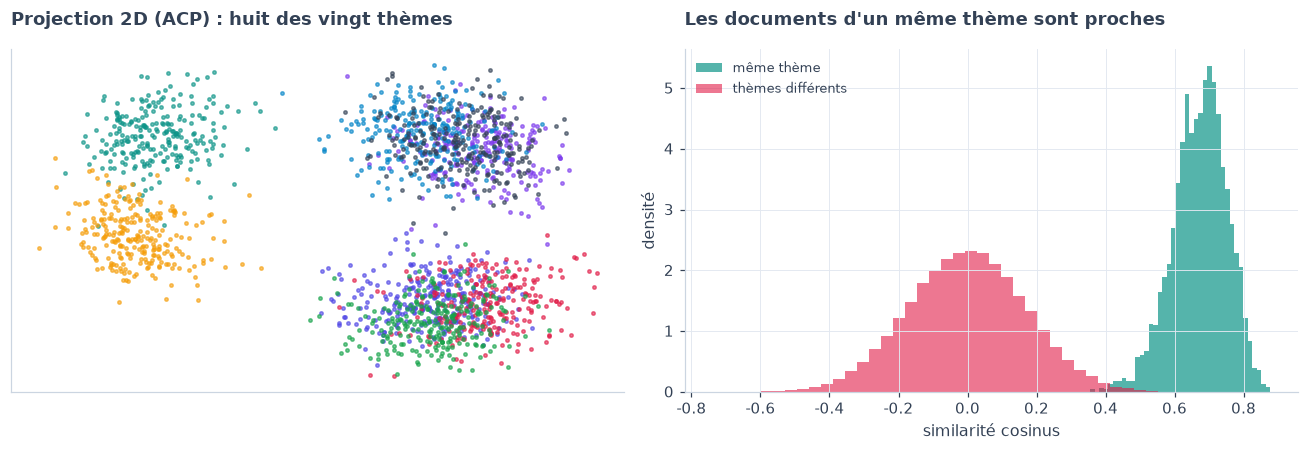

In [4]:
X, theme = V.make_embeddings(5_000, dim=32, n_topics=20, seed=0)
Q = V.make_queries(X, 200, seed=1)
i, j = 10, 3456
cos = float(X[i] @ X[j])
print(f"cos = {cos:.4f} ; ||a - b||^2 = {np.sum((X[i] - X[j]) ** 2):.4f} ; 2(1 - cos) = {2 * (1 - cos):.4f}")
# projection 2D (ACP) pour visualiser les thèmes
Xc = X - X.mean(axis=0)
_, _, Vt = np.linalg.svd(Xc[:2000], full_matrices=False)
P2 = Xc @ Vt[:2].T
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
for t_, c_ in zip(range(8), COLORS):
    m_ = theme == t_
    ax.scatter(P2[m_, 0], P2[m_, 1], color=c_, s=5, alpha=0.6)
ax.set_title("Projection 2D (ACP) : huit des vingt thèmes")
ax.set_xticks([]); ax.set_yticks([])
ax = axes[1]
meme = X[:400] @ X[:400].T
mask = theme[:400, None] == theme[None, :400]
iu = np.triu_indices(400, 1)
ax.hist(meme[iu][mask[iu]], bins=40, color=TEAL, alpha=0.7, density=True, label="même thème")
ax.hist(meme[iu][~mask[iu]], bins=40, color=ROSE, alpha=0.6, density=True, label="thèmes différents")
ax.set_xlabel("similarité cosinus"); ax.set_ylabel("densité")
ax.set_title("Les documents d'un même thème sont proches")
ax.legend(fontsize=8.5)
finish(fig)
plt.show()

> **À retenir.** Sur des vecteurs normalisés, distance euclidienne et cosinus sont
> équivalents pour classer des voisins : $\lVert a-b\rVert^2 = 2(1-\cos)$.

## 3. L'index plat (section *Vector Embeddings*, *Flat indexes*)

Le plus simple : stocker les vecteurs tels quels et comparer la requête à **tous**.
Résultat **exact**, coût **linéaire** : $n$ produits scalaires de dimension $d$ par
requête. Il sert de référence (la « vérité ») pour mesurer le **rappel** des index
approchés : la fraction des $k$ vrais plus proches voisins effectivement renvoyés.

In [5]:
flat = V.FlatIndex(X)
t0 = time.perf_counter()
verite = [flat.search(q, 10) for q in Q]
t_flat = (time.perf_counter() - t0) / len(Q)
print(f"index plat : {flat.distance_computations // len(Q)} distances par requête, {t_flat * 1e3:.2f} ms par requête")
n_docs = np.array([1e6, 1e7, 1e8, 1e9])
pd.DataFrame({"mémoire (Go), d = 1024, float32": n_docs * 1024 * 4 / 1e9,
              "temps par requête à 50 Go/s de bande passante (ms)": n_docs * 1024 * 4 / 50e9 * 1e3},
             index=[f"{int(n):,} documents".replace(",", " ") for n in n_docs]).round(1)

index plat : 5000 distances par requête, 0.02 ms par requête


,"mémoire (Go), d = 1024, float32",temps par requête à 50 Go/s de bande passante (ms)
1 000 000 documents,4.1,81.9
10 000 000 documents,41.0,819.2
100 000 000 documents,409.6,8192.0
1 000 000 000 documents,4096.0,81920.0


Le tableau donne l'ordre de grandeur pour de vrais embeddings (1 024 dimensions en
`float32`) : à cent millions de documents, il faut 400 Go de vecteurs et chaque requête
doit tous les relire, soit environ 8 secondes même au débit maximal de la mémoire.
D'où les index **approchés**, qui sacrifient un peu de rappel.

> **À retenir.** L'index plat est exact mais coûte $O(n\,d)$ par requête ; il sert de
> référence pour mesurer le rappel des index approchés.

## 4. L'index IVF (section *Vector Embeddings*, *Inverted file (IVF) indexes*)

**Idée.** Partitionner l'espace en groupes (ici par **k-moyennes**) ; chaque vecteur est
rangé dans la liste de son **centroïde** le plus proche (d'où le nom de fichier inversé,
par analogie avec les postings lists). Une requête compare la requête aux centroïdes,
puis ne parcourt que les `nprobe` listes les plus proches : les **sondes**. Plus de
sondes = plus de rappel, mais plus de calculs. Le résultat est **approché** : un vrai
voisin peut se trouver juste de l'autre côté d'une frontière. Visualisons-le en 2D.

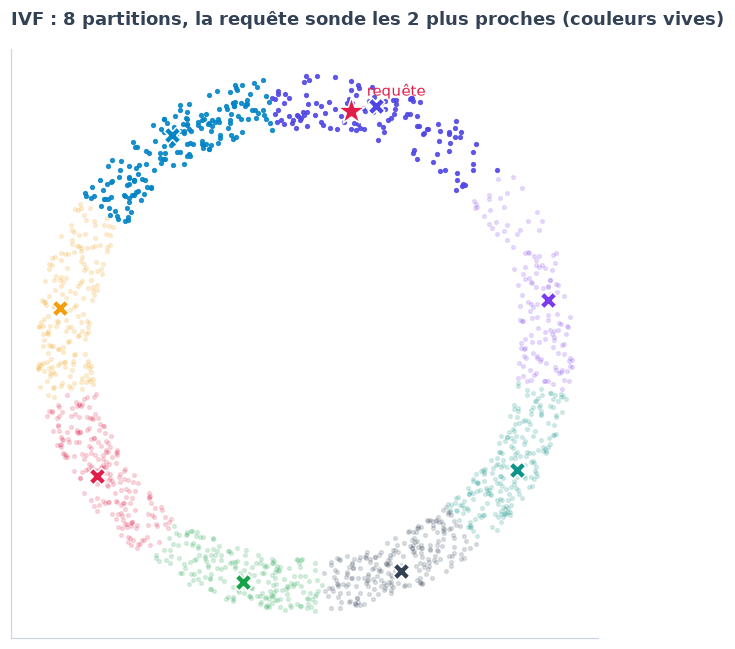

In [6]:
X2, _ = V.make_embeddings(1500, dim=2, n_topics=6, spread=0.6, seed=3)
X2 = X2 * (1 + 0.25 * np.random.default_rng(3).random((len(X2), 1)))  # rayons variés, pour l'œil
ivf2 = V.IVFIndex(X2 / np.linalg.norm(X2, axis=1, keepdims=True), nlist=8, seed=0)
q2 = V.normalize(np.array([0.2, 1.0]))
cs = ivf2.centroids @ q2
sondes = np.argsort(-cs)[:2]
assign = np.empty(len(X2), dtype=int)
for c_, lst in enumerate(ivf2.lists):
    assign[lst] = c_
fig, ax = plt.subplots(figsize=(6.5, 6))
pal = COLORS * 2
for c_ in range(len(ivf2.lists)):
    pts = X2[assign == c_]
    ax.scatter(pts[:, 0], pts[:, 1], s=6, color=pal[c_], alpha=0.85 if c_ in sondes else 0.15)
    ax.scatter(*(ivf2.centroids[c_] * 1.15), marker="X", s=120, color=pal[c_], edgecolor="white", zorder=4)
ax.scatter(*(q2 * 1.1), marker="*", s=350, color=ROSE, edgecolor="white", zorder=5)
ax.annotate("requête", q2 * 1.1, xytext=(10, 10), textcoords="offset points", color=ROSE, fontsize=10)
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("IVF : 8 partitions, la requête sonde les 2 plus proches (couleurs vives)")
plt.tight_layout(); plt.show()

Mesurons sur le nuage à 32 dimensions : rappel@10 et nombre de distances calculées par
requête, pour 64 partitions et un nombre de sondes croissant.

In [7]:
ivf = V.IVFIndex(X, nlist=64, seed=0)
rows = []
for nprobe in [1, 2, 4, 8, 16, 32, 64]:
    ivf.distance_computations = 0
    rec = np.mean([V.recall_at_k(ivf.search(q, 10, nprobe), t) for q, t in zip(Q, verite)])
    rows.append(dict(nprobe=nprobe, rappel=rec, distances=ivf.distance_computations / len(Q)))
res_ivf = pd.DataFrame(rows)
res_ivf

,nprobe,rappel,distances
0,1,0.643,173.740
1,2,0.880,267.985
2,4,0.974,428.090
3,8,1.000,732.625
4,16,1.000,1339.360
5,32,1.000,2573.150
6,64,1.000,5064.000


Avec une seule sonde, on ne calcule qu'environ 2 % des distances mais on rate une bonne
partie des voisins ; quelques sondes suffisent pour un rappel proche de 1, et avec
toutes les sondes on retrouve l'index plat (rappel 1, plus les 64 centroïdes).

> **À retenir.** L'IVF partitionne l'espace autour de centroïdes et ne parcourt que les
> `nprobe` partitions les plus proches : on règle le compromis rappel / coût par le
> nombre de sondes.

## 5. L'index HNSW (section *Vector Embeddings*, *Hierarchical Navigable Small World*)

**Idée.** Un **graphe de proximité** : chaque vecteur est un nœud relié à quelques
voisins proches. Pour chercher, on part d'un nœud et on se déplace de proche en proche
vers la requête (recherche gloutonne). Pour aller vite de loin, HNSW empile des
**couches** : chaque nœud reçoit un niveau aléatoire (loi géométrique), les couches
hautes sont clairsemées et servent d'**autoroutes**, la couche 0 contient tous les nœuds.
La recherche trouve le plus proche voisin dans la couche du haut, descend au **même
nœud** dans la couche inférieure, plus dense, et recommence. Le paramètre `ef` (taille de
la liste de candidats dans la couche 0) règle le compromis rappel / coût. Visualisons
une recherche en 2D.

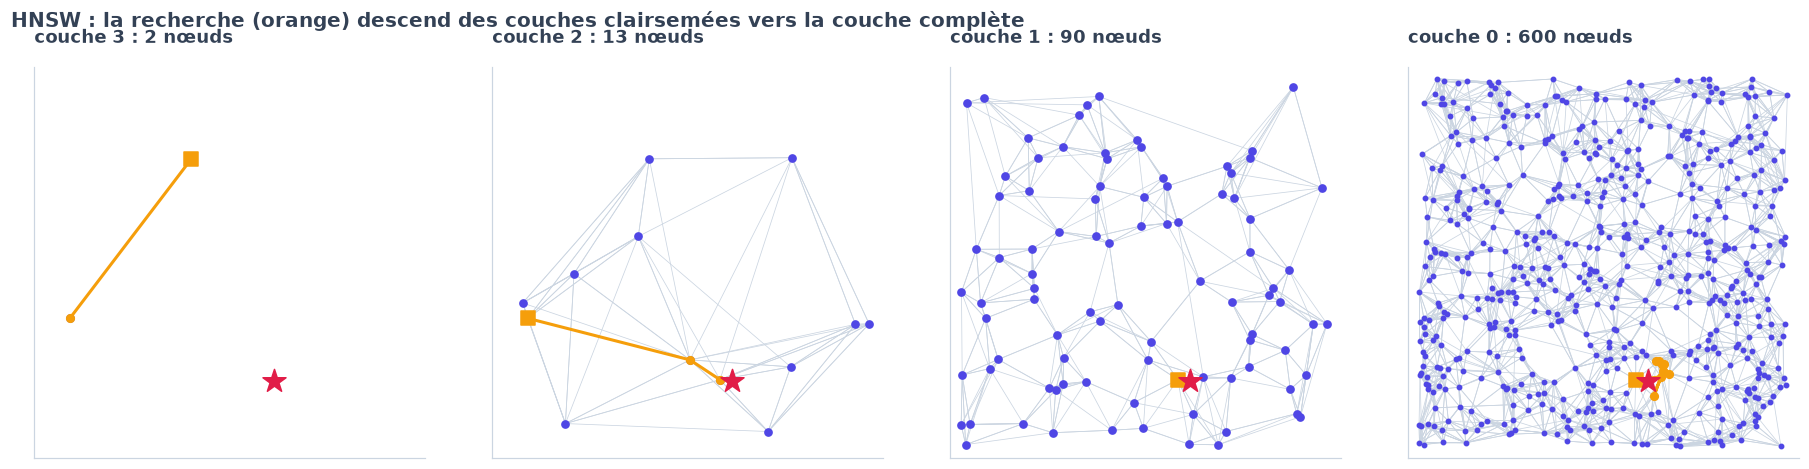

In [8]:
X2n = np.random.default_rng(5).random((600, 2))  # points du plan, distance euclidienne
h2 = V.HNSWIndex(X2n, M=6, ef_construction=30, seed=1, metric="l2")
q = np.array([0.62, 0.18])
trace = []
trouve = h2.search(q, k=1, ef=8, trace=trace)
n_layers = len(h2.layers)
fig, axes = plt.subplots(1, n_layers, figsize=(4.2 * n_layers, 4.3))
for l in range(n_layers - 1, -1, -1):
    ax = axes[n_layers - 1 - l]
    g = h2.layers[l]
    for a, nbrs in g.items():
        for b in nbrs:
            ax.plot(*X2n[[a, b]].T, color="#CBD5E1", lw=0.5, zorder=1)
    nodes = list(g)
    ax.scatter(*X2n[nodes].T, s=8 if l == 0 else 22, color=INDIGO, zorder=2)
    chemin = [n for (ll, n) in trace if ll == l]
    if chemin:
        ax.plot(*X2n[chemin].T, "-o", color=AMBER, lw=2, ms=5, zorder=3)
        ax.scatter(*X2n[chemin[0]], s=90, color=AMBER, marker="s", zorder=4)
    ax.scatter(*q, marker="*", s=250, color=ROSE, zorder=5)
    ax.set_title(f"couche {l} : {len(g)} nœuds")
    ax.set_xlim(-0.03, 1.03); ax.set_ylim(-0.03, 1.03)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
finish(fig, "HNSW : la recherche (orange) descend des couches clairsemées vers la couche complète")
plt.show()

Le carré orange marque le point d'entrée de chaque couche : c'est le nœud trouvé dans la
couche du dessus. Quelques sauts dans les couches clairsemées amènent la recherche près
de la requête ; la couche 0, dense, affine le résultat. (Cette démonstration utilise la
distance euclidienne dans le plan, `metric="l2"`, plus lisible à l'œil.)

Mesurons maintenant sur le nuage à 32 dimensions le rappel et le coût selon `ef`, et
comparons les trois index sur un même graphique rappel / coût.

construction : 4.4 s (324 distances par insertion) ; couches : [5000, 410, 37, 3]


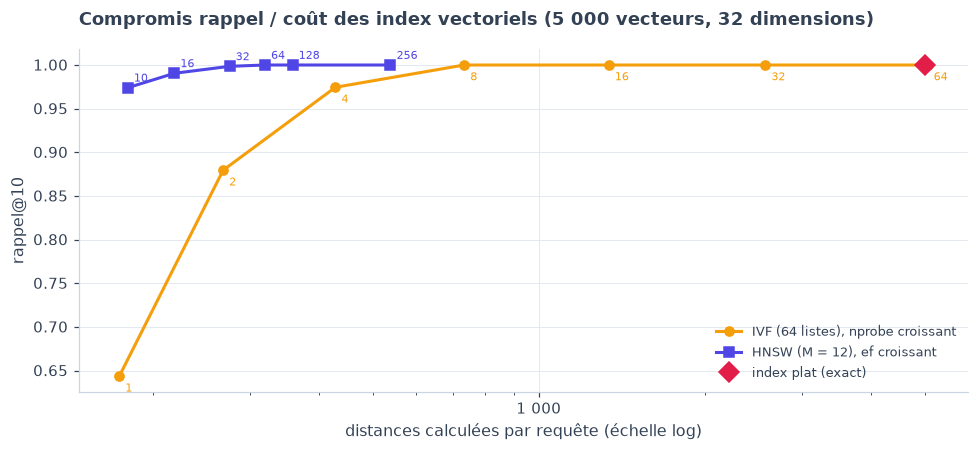

,ef,rappel,distances
0,10,0.974,180.060
1,16,0.990,218.605
2,32,0.998,275.315
3,64,1.000,319.095
4,128,1.000,358.110
5,256,1.000,538.675


In [9]:
t0 = time.perf_counter()
hnsw = V.HNSWIndex(X, M=12, ef_construction=80, seed=0)
t_build = time.perf_counter() - t0
rows = []
for ef in [10, 16, 32, 64, 128, 256]:
    hnsw.distance_computations = 0
    rec = np.mean([V.recall_at_k(hnsw.search(q, 10, ef=ef), t) for q, t in zip(Q, verite)])
    rows.append(dict(ef=ef, rappel=rec, distances=hnsw.distance_computations / len(Q)))
res_h = pd.DataFrame(rows)
print(f"construction : {t_build:.1f} s ({hnsw.build_distance_computations / len(X):.0f} distances par insertion) ;",
      f"couches : {hnsw.layer_sizes()}")
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(res_ivf.distances, res_ivf.rappel, "o-", color=AMBER, label="IVF (64 listes), nprobe croissant")
for _, r in res_ivf.iterrows():
    ax.annotate(f"{int(r.nprobe)}", (r.distances, r.rappel), xytext=(4, -10), textcoords="offset points",
                fontsize=7.5, color=AMBER)
ax.plot(res_h.distances, res_h.rappel, "s-", color=INDIGO, label="HNSW (M = 12), ef croissant")
for _, r in res_h.iterrows():
    ax.annotate(f"{int(r.ef)}", (r.distances, r.rappel), xytext=(4, 4), textcoords="offset points",
                fontsize=7.5, color=INDIGO)
ax.plot([len(X)], [1.0], "D", color=ROSE, ms=9, label="index plat (exact)")
ax.set_xscale("log"); S.plain_log_ticks(ax, "x")
ax.set_xlabel("distances calculées par requête (échelle log)"); ax.set_ylabel("rappel@10")
ax.set_title("Compromis rappel / coût des index vectoriels (5 000 vecteurs, 32 dimensions)")
ax.legend(fontsize=8.5, loc="lower right")
plt.tight_layout(); plt.show()
res_h

Les deux index approchés atteignent un rappel élevé en calculant une petite fraction
des 5 000 distances de l'index plat. Leurs compromis diffèrent : l'IVF est simple et
compact (un centroïde par liste), mais il faut l'entraîner et ses partitions
vieillissent quand les données changent ; HNSW s'insère au fil de l'eau et donne
souvent un excellent rappel à faible coût (ici, un rappel proche de 1 pour quelques
centaines de distances), au prix d'un graphe (des dizaines de références par vecteur)
en mémoire et d'une construction coûteuse. Un détail compte beaucoup : le choix des
voisins de chaque nœud. Garder simplement les plus proches referme chaque groupe de
points sur lui-même ; l'heuristique de HNSW (garder un candidat seulement s'il est plus
proche du nœud que des voisins déjà retenus) préserve des liens vers les autres
régions, ce que fait `V.HNSWIndex._select`. Faiss propose de nombreuses variantes des
deux familles, et l'extension pgvector de PostgreSQL implémente IVF et HNSW.

> **À retenir.** IVF (partitions + sondes) et HNSW (graphe hiérarchique + `ef`) sont des
> index **approchés** : on règle le rappel contre le coût. HNSW est souvent le meilleur
> compromis, au prix de la mémoire et du temps de construction.

## 6. Pourquoi pas un R-tree ? La malédiction de la dimension (section *Vector Embeddings*)

Le livre note que les R-trees du cours 4 fonctionnent mal pour des vecteurs à beaucoup
de dimensions. Une raison profonde : en grande dimension, **toutes les distances se
ressemblent**. Le rapport entre la distance du plus proche voisin et celle du plus
lointain tend vers 1, si bien qu'aucun découpage de l'espace en boîtes ne permet
d'écarter de grandes régions sans risque. Mesurons-le sur des points uniformes.

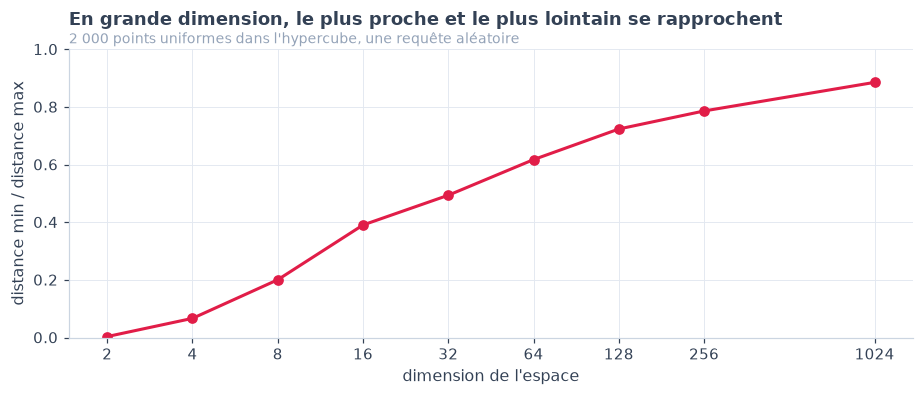

In [10]:
rng = np.random.default_rng(0)
rows = []
for dim in [2, 4, 8, 16, 32, 64, 128, 256, 1024]:
    P = rng.random((2000, dim))
    qq = rng.random(dim)
    dist = np.linalg.norm(P - qq, axis=1)
    rows.append(dict(dimension=dim, rapport=dist.min() / dist.max()))
mal = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 3.7))
ax.plot(mal.dimension, mal.rapport, "o-", color=ROSE)
ax.set_xscale("log", base=2)
ax.set_xticks(mal.dimension, mal.dimension.astype(str)); ax.minorticks_off()
ax.set_ylim(0, 1)
ax.set_xlabel("dimension de l'espace"); ax.set_ylabel("distance min / distance max")
ax.set_title("En grande dimension, le plus proche et le plus lointain se rapprochent")
subtitle(ax, "2 000 points uniformes dans l'hypercube, une requête aléatoire")
plt.tight_layout(); plt.show()

En 2 dimensions, le plus proche voisin est des centaines de fois plus près que le plus
lointain ; en 1 024 dimensions, le rapport dépasse 0,8. Les vrais embeddings ne sont pas
uniformes (ils ont une structure, heureusement), mais l'effet suffit à rendre
inefficaces les index spatiaux classiques : il faut des index conçus pour les plus
proches voisins approchés.

> **À retenir.** En grande dimension, les distances se concentrent : les découpages
> d'espace des R-trees n'élaguent plus rien, d'où les index vectoriels dédiés.